In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import xgboost as xgb 
from xgboost import XGBRegressor

In [2]:
path = '/Users/siobhankassem/Desktop/USC/Classes/Fall 2026/Python Data Science/Datasets/Waves_2023.txt'
waves = pd.read_csv(path, sep=r"\s+")
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)
waves

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
0,2023,1,1,0,26,1.12,12.50,7.69,269,15.3
1,2023,1,1,0,56,1.16,11.76,7.34,272,15.3
2,2023,1,1,1,26,1.20,12.50,7.08,268,15.3
3,2023,1,1,1,56,1.25,10.53,7.33,268,15.4
4,2023,1,1,2,26,1.27,10.53,7.57,268,15.5
...,...,...,...,...,...,...,...,...,...,...
17280,2023,12,31,21,56,2.01,14.29,11.19,270,16.7
17281,2023,12,31,22,26,1.75,15.38,10.37,267,16.7
17282,2023,12,31,22,56,1.79,13.33,10.50,268,16.8
17283,2023,12,31,23,26,1.66,14.29,10.32,271,16.8


In [3]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy() # dropping our target
df_y = wavesML['WVHT'].to_numpy() # what we ar predicting, what we removed from above

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10) # making training and test data
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10) # taking 10% of the training data and setting it aside for validation data

In [4]:
model = XGBRegressor(n_estimators=25)
model = model.fit(X_train, y_train)
yPred = model.predict(X_val)

In [5]:
y_pred_train = model.predict(X_train)
train_mse = mean_squared_error(y_train, y_pred_train)
print("Train MSE: ", train_mse)

mean_squared_error(yPred,y_val)
print("Validation MSE: ", mean_squared_error(yPred,y_val))

Train MSE:  0.07343656606129609
Validation MSE:  0.08765195333590134


In [6]:
y_pred_test = model.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred_test)
print("Test MSE: ", test_mse)

Test MSE:  0.08774714973255167


In [7]:
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_val)
mean_squared_error(y_val, y_pred)
print("Linear Reg MSE: ", mean_squared_error(y_val, y_pred))

Linear Reg MSE:  0.19624908309864222


I think that the boosted regression tree performed better than the linear regression i chose because the MSE is lower. This is maybe because the boostes tree model can represent non-linear relationships that the linear model couldnt.  

Cost function: MSE

Hyperparameters: I dont think I initially optimized any parameters except for the number of boosting iterations. I ran this model again and chose to optimize the max depth and the learning rate with arbitrary values, and the validation MSE increased compared to the default settings in the last model. So I dont think optimizing helped my model at all, or I chose the wrong values to optimize by. 

In [8]:
model_optimized = XGBRegressor(n_estimators=25, max_depth = 15, learning_rate = .5)
model_optimized = model_optimized.fit(X_train, y_train)
yPred = model_optimized.predict(X_val)

mean_squared_error(yPred,y_val)
print("Validation MSE: ", mean_squared_error(yPred,y_val))

Validation MSE:  0.0861647617745077


<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

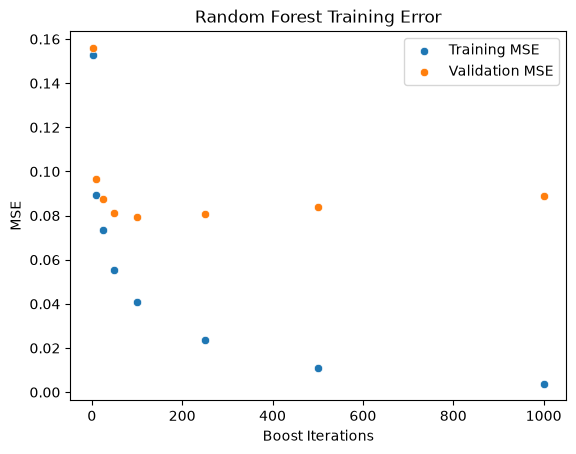

In [9]:
boost = [2, 10, 25, 50, 100,
250, 500, 1000]
scores = []
val_scores = []

for i in boost:
    model = XGBRegressor(n_estimators=i)
    model.fit(X_train, y_train)

    train_mse = mean_squared_error(y_train, model.predict(X_train))
    scores.append(train_mse)

    val_scores.append(mean_squared_error(y_val, model.predict(X_val)))

    
sns.scatterplot(x=boost,y=scores, label ="Training MSE")
sns.scatterplot(x=boost,y=val_scores, label ="Validation MSE")

plt.xlabel("Boost Iterations")
plt.ylabel("MSE")
plt.title("Random Forest Training Error")
plt.legend

Overfitting seems to happen with 1000 trees because the training MSE approaches 0, while the validation data continues to increase. So the model is overfitting to the patterns in the training data, and when it sees the validation data the performance is not as good. 

If we were to only look at the training data, it would seem like the the model is working near "perfectly", but the validation data shows that this was just because it was overfit

In [11]:
model_stop = XGBRegressor(n_estimators=2000, early_stopping_rounds=10)
model_stop = model_stop.fit(X_train, y_train, eval_set=[(X_val, y_val)])

yPred = model_stop.predict(X_val)

[0]	validation_0-rmse:0.44885
[1]	validation_0-rmse:0.39508
[2]	validation_0-rmse:0.36528
[3]	validation_0-rmse:0.34550
[4]	validation_0-rmse:0.33409
[5]	validation_0-rmse:0.32604
[6]	validation_0-rmse:0.32042
[7]	validation_0-rmse:0.31636
[8]	validation_0-rmse:0.31320
[9]	validation_0-rmse:0.31059
[10]	validation_0-rmse:0.30995
[11]	validation_0-rmse:0.30758
[12]	validation_0-rmse:0.30663
[13]	validation_0-rmse:0.30400
[14]	validation_0-rmse:0.30277
[15]	validation_0-rmse:0.30229
[16]	validation_0-rmse:0.30171
[17]	validation_0-rmse:0.30080
[18]	validation_0-rmse:0.30046
[19]	validation_0-rmse:0.30004
[20]	validation_0-rmse:0.29999
[21]	validation_0-rmse:0.29989
[22]	validation_0-rmse:0.29863
[23]	validation_0-rmse:0.29714
[24]	validation_0-rmse:0.29606
[25]	validation_0-rmse:0.29428
[26]	validation_0-rmse:0.29359
[27]	validation_0-rmse:0.29386
[28]	validation_0-rmse:0.29380
[29]	validation_0-rmse:0.29349
[30]	validation_0-rmse:0.29315
[31]	validation_0-rmse:0.29258
[32]	validation_0-

As I increased my number of iterations from 25 up to 3000, it seemed that the early stopping stoped at 100 each time the n>100. So 100 is the optimal amount of boosting iterations. 